In [1]:
# Keep imports and data/output paths relative to the repository root.
import os
import sys
from pathlib import Path
from datetime import datetime
from uuid import uuid4

for repository_dir in (Path.cwd(), *Path.cwd().parents):
    if (repository_dir / ".geofm-root").is_file():
        os.chdir(repository_dir)
        break
else:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if "src" not in sys.path:
    sys.path.insert(0, "src")

EXPERIMENT_NAME = "sen1floods11/croma/upernet_s2"
NOTEBOOK_PATH = "experiments/sen1floods11/croma/upernet_s2/02C_croma_on_sen1floods11_test_UperNet_S2.ipynb"


In [2]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import math
import json
import pandas as pd

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA

In [3]:
from croma_upernet_pangaea import (
    UPerNetHead, filter_labeled_training_pairs, random_labeled_crop, PANGAEA_REVISION
)
from einops import rearrange
from segmentation_metrics import (binary_metrics, confusion_counts, METRIC_KEYS,
    metric_table, save_per_chip_metrics, clean_json, plot_metric_history)

CROP_SIZE = 120
IGNORE_INDEX = 255
SCHEMA = "croma_s2_upernet_pangaea_v1"
S2_BANDS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13]  # Exclude B10/cirrus.
# Same pinned PANGAEA dataset statistics as S1, selecting the optical channels.
PREPROCESSING = {
    "name": "pangaea_sen1floods11_optical_mean_std", "modality": "optical",
    "bands": S2_BANDS,
    "band_names": ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"],
    "mean": [1626.91600224, 1396.03470631, 1364.06118417, 1218.22847919,
             1466.07290663, 2386.90297537, 2845.61256277, 2622.95796892,
             3077.48221481, 486.87436782, 2030.64763024, 1179.16607221],
    "std": [700.17133846, 739.09452682, 735.2482388, 864.936695,
            776.8803358, 921.36834309, 1084.37346097, 1022.63418007,
            1196.44255318, 336.61105431, 980.87061347, 764.60836557],
    "nan_to_num": "numpy_default_before_normalization", "clip": None,
    "ignore_index": IGNORE_INDEX, "source_revision": PANGAEA_REVISION,
}

def load_split_paths(csv_file, x_dir, y_dir):
    pairs = []
    with open(csv_file, newline="") as handle:
        for x_name, y_name in csv.reader(handle):
            chip = x_name.strip().removesuffix("_S1Hand.tif")
            if y_name.strip() != chip + "_LabelHand.tif":
                raise ValueError(f"Mismatched split row: {x_name}, {y_name}")
            x_path, y_path = Path(x_dir) / (chip + "_S2Hand.tif"), Path(y_dir) / y_name.strip()
            if not x_path.is_file() or not y_path.is_file():
                raise FileNotFoundError(f"Missing pair: {x_path}, {y_path}")
            with rasterio.open(x_path) as x, rasterio.open(y_path) as y:
                if (x.count != 13 or x.shape != y.shape or x.crs != y.crs
                        or not x.transform.almost_equals(y.transform, precision=1e-10)):
                    raise ValueError(f"Band/grid mismatch: {chip}")
            pairs.append((x_path, y_path))
    return pairs

def load_image_pair(pair):
    with rasterio.open(pair[0]) as src:
        image = src.read(S2_BANDS, out_dtype="float32", masked=True).filled(np.nan)
    with rasterio.open(pair[1]) as src:
        mask = src.read(1).astype(np.int64)
    return image, mask

def prepare_sample(data):
    raw, mask = data
    image = torch.as_tensor(np.nan_to_num(raw), dtype=torch.float32)
    mask = torch.as_tensor(mask, dtype=torch.long).clone()
    mask[mask == -1] = IGNORE_INDEX
    if image.ndim != 3 or image.shape[0] != 12 or image.shape[-2:] != mask.shape:
        raise ValueError("Expected aligned 12-band optical image and label.")
    if not set(torch.unique(mask).tolist()).issubset({0, 1, IGNORE_INDEX}):
        raise ValueError("Unexpected label values.")
    mean = image.new_tensor(PREPROCESSING["mean"])[:, None, None]
    std = image.new_tensor(PREPROCESSING["std"])[:, None, None]
    image = (image - mean) / std
    if not torch.isfinite(image).all():
        raise ValueError("Nonfinite normalized optical input.")
    return image, mask

class Sen1Floods11Dataset(Dataset):
    def __init__(self, data_list, preprocess_func):
        self.data_list, self.preprocess_func = data_list, preprocess_func
    def __len__(self):
        return len(self.data_list)
    def __getitem__(self, index):
        return self.preprocess_func(load_image_pair(self.data_list[index]))

def audit_s2_pairs(pairs):
    rows = []
    for pair in pairs:
        raw, _ = load_image_pair(pair)
        valid = np.isfinite(raw).all(axis=0)
        rows.append({"image": str(pair[0]), "usable_pixel_fraction": float(valid.mean()),
                     "exclude_missing_s2": not bool(valid.any())})
    return pd.DataFrame(rows)

class CROMAUPerNet(nn.Module):
    def __init__(self, croma, head):
        super().__init__()
        self.croma = croma.requires_grad_(False)
        self.head = head
        self.croma.eval()
        if max(head.out_indices) >= len(croma.s2_encoder.transformer.layers):
            raise ValueError('Requested blocks exceed the optical encoder depth.')
        if head.config['in_channels'] != croma.encoder_dim:
            raise ValueError('Decoder channel count does not match CROMA.')

    def train(self, mode=True):
        super().train(mode)
        self.croma.eval()
        return self

    @torch.no_grad()
    def extract_features(self, images):
        encoder = self.croma.s2_encoder
        p = encoder.patch_size
        h, w = images.shape[-2:]
        if h != w or h % p or (h // p) * (w // p) != self.croma.num_patches:
            raise ValueError('Input tile must match the square CROMA image_resolution.')
        x = rearrange(images, 'b c (h i) (w j) -> b (h w) (c i j)', i=p, j=p)
        x = encoder.linear_input(x)
        bias = self.croma.attn_bias.to(device=x.device, dtype=x.dtype)
        features = []
        # Capture the full residual stream AFTER attention and FFN, not FFN outputs alone.
        # Match PANGAEA: early selected streams remain raw; normalize only the final selected stream.
        for index, (attention, ffn) in enumerate(encoder.transformer.layers):
            x = x + attention(x, bias)
            x = x + ffn(x)
            if index in self.head.out_indices:
                selected = encoder.transformer.norm_out(x) if index == self.head.out_indices[-1] else x
                features.append(selected.transpose(1, 2).reshape(x.shape[0], x.shape[2], h // p, w // p))
            if index == self.head.out_indices[-1]:
                break
        return features

    def forward(self, images):
        logits = self.head(self.extract_features(images))
        return F.interpolate(logits, size=images.shape[-2:], mode='bilinear', align_corners=False)

def latest_completed_checkpoint(run_root):
    candidates = []
    for manifest in Path(run_root).glob('train_*/run.json'):
        metadata = json.loads(manifest.read_text(encoding='utf-8'))
        if metadata.get('schema') != SCHEMA:
            continue
        history_path = manifest.parent / 'croma_training_history.json'
        if not history_path.is_file():
            continue
        history = json.loads(history_path.read_text(encoding='utf-8'))
        checkpoint = manifest.parent / Path(metadata['checkpoint']).name
        if history.get('epochs_completed') == metadata.get('epochs') and checkpoint.is_file():
            candidates.append((metadata['started_at'], checkpoint))
    if not candidates:
        raise FileNotFoundError('No completed UPerNet run found. Run the training notebook first.')
    return max(candidates, key=lambda item: item[0])[1]


#### **First things first**


In [4]:
model_name = "croma_large_upernet_pangaea_s2.pt"
# None selects the latest completed UPerNet run, using its best validation-mIoU checkpoint.
# Set a relative Path here only to evaluate a specific older run.
checkpoint_path = None
TILE_BATCH_SIZE = 8


In [5]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/croma/CROMA_large.pt"

path_to_the_dataset = "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "datasets/sen1floods11/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S2Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_permanent_water = path_to_the_dataset + "JRCWaterHand"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)

cuda


#### **Functions**

In [6]:
## Note here mIoU is not being computed!
def preprocess_test(data):
   
    return prepare_sample(data)

#### **Creating datasets**

In [7]:

# Verify official split membership, counts, disjointness, and S2/label alignment.
split_files = {"train": "flood_train_data.csv", "valid": "flood_valid_data.csv",
               "non_bol": "flood_test_data.csv", "bol": "flood_bolivia_data.csv"}
expected_counts = {"train": 252, "valid": 89, "non_bol": 90, "bol": 15}
all_splits = {name: load_split_paths(Path(path_to_the_dataset_index) / filename, path_to_X, path_to_Y)
              for name, filename in split_files.items()}
for name, pairs in all_splits.items():
    assert len(pairs) == expected_counts[name], (name, len(pairs))
    assert len({x.stem for x, _ in pairs}) == len(pairs), f"Duplicates in {name}"
for i, name in enumerate(all_splits):
    for other in list(all_splits)[i+1:]:
        assert not ({x.stem for x, _ in all_splits[name]} & {x.stem for x, _ in all_splits[other]})
print("Verified S2/label grids and disjoint split counts:", {k: len(v) for k, v in all_splits.items()})

test_data_non_bolivia = all_splits["non_bol"]
test_data_bolivia = all_splits["bol"]


Verified S2/label grids and disjoint split counts: {'train': 252, 'valid': 89, 'non_bol': 90, 'bol': 15}


In [8]:
print(f"Non bolivia test samples: {len(test_data_non_bolivia)}")
print(f"Bolivia test samples: {len(test_data_bolivia)}")

Non bolivia test samples: 90
Bolivia test samples: 15


In [9]:
print(test_data_non_bolivia[0])
print(test_data_bolivia[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S2Hand/Ghana_313799_S2Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_313799_LabelHand.tif'))
(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S2Hand/Bolivia_103757_S2Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif'))


In [10]:
test_dataset_non_bolivia = Sen1Floods11Dataset(
 data_list = test_data_non_bolivia,
 preprocess_func=preprocess_test
)

test_dataset_bolivia = Sen1Floods11Dataset(
 data_list = test_data_bolivia,
 preprocess_func=preprocess_test
)

In [11]:
test_loader_non_bolivia = DataLoader(
    test_dataset_non_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_bolivia = DataLoader(
    test_dataset_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

#### **Model**

In [12]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='optical', 
                        image_resolution=120)

croma = croma.to(device)

Initializing optical encoder


In [13]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s2_encoder): ViT(
    (linear_input): Linear(in_features=768, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-23): 24 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

#### **Creating the head**

In [14]:
if checkpoint_path is None:
    checkpoint_path = latest_completed_checkpoint(Path("runs") / EXPERIMENT_NAME)
checkpoint_path = Path(checkpoint_path)
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
if checkpoint.get("schema") != SCHEMA:
    raise ValueError("This notebook requires a PANGAEA-aligned optical UPerNet checkpoint.")
if checkpoint.get("preprocessing") != PREPROCESSING:
    raise ValueError("Checkpoint preprocessing does not match this notebook.")
if checkpoint.get("crop_size") != CROP_SIZE:
    raise ValueError("Checkpoint crop size does not match this notebook.")
if checkpoint.get("pretrained_weights") != pretrained_path:
    raise ValueError("Checkpoint requires different pretrained CROMA weights.")
head = UPerNetHead(**checkpoint["head_config"]).to(device)
print(f"Selected checkpoint: {checkpoint_path}")


Selected checkpoint: runs\croma_sen1floods11\UperNet_Head_S2\train_croma_large_upernet_pangaea_s2_2026-10-24_17-53-29_579252_2f9eec0f\croma_large_upernet_pangaea_s2.pt


In [15]:
head.load_state_dict(checkpoint["head_state_dict"], strict=True)
print(f"UPerNet weights loaded: epoch {checkpoint['epoch']}, "
      f"validation mIoU {checkpoint['best_val_miou']:.4f}")


UPerNet weights loaded: epoch 56, validation mIoU 0.9054


In [16]:
model = CROMAUPerNet(croma, head).to(device)
model.eval()


CROMAUPerNet(
  (croma): PretrainedCROMA(
    (s2_encoder): ViT(
      (linear_input): Linear(in_features=768, out_features=1024, bias=True)
      (transformer): BaseTransformer(
        (layers): ModuleList(
          (0-23): 24 x ModuleList(
            (0): Attention(
              (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
              (to_out): Linear(in_features=1024, out_features=1024, bias=True)
              (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (1): FFN(
              (net): Sequential(
                (0): Linear(in_features=1024, out_features=4096, bias=True)
                (1): GELU(approximate='none')
                (2): Dropout(p=0.0, inplace=False)
                (3): Linear(in_features=4096, out_features=1024, bias=True)
              )
              (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bia

In [17]:
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)


In [18]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=None,
    tile_batch_size=TILE_BATCH_SIZE
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained UPerNet head.

    image:
        Tensor [12, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        None uses the PANGAEA evenly spaced sliding-window grid.

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 12
    assert H >= tile_size and W >= tile_size
    assert stride is None or 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        import math
        # Upstream default: 5 evenly spaced windows per axis for 512px / 120px.
        count = math.ceil(length / tile_size) if stride is None else math.ceil((length - tile_size) / stride) + 1
        return torch.linspace(0, length - tile_size, count).round().long().tolist()

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen CROMA + UPerNet head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)

@torch.inference_mode()
def test(
    model,
    valid_loader,
    criterion,
    device,
    save_predictions=False,
    save_dir=None,
    test_data=None,
    save_metrics=True
):
    model.eval()

    if criterion.reduction != "mean":
        raise ValueError("This implementation expects reduction='mean'.")

    save_dir = run_results_dir / "test" if save_dir is None else Path(save_dir)

    if save_predictions:
        if test_data is None:
            raise ValueError("Provide test_data to save georeferenced predictions.")

        if not hasattr(valid_loader.dataset, "data_list"):
            raise ValueError("Expected a dataset with data_list.")

        if list(test_data) != list(valid_loader.dataset.data_list):
            raise ValueError("test_data must match the dataset order.")

        if valid_loader.batch_size != 1:
            raise ValueError("Use batch_size=1 to save predictions.")

        if not isinstance(
            valid_loader.sampler,
            torch.utils.data.SequentialSampler
        ):
            raise ValueError("Use shuffle=False when saving predictions.")

    if save_predictions or save_metrics:
        save_dir.mkdir(parents=True, exist_ok=True)

    total_loss = 0.0
    total_weight = 0.0

    TP = FP = FN = TN = 0
    sample_idx = 0
    per_chip_metrics = []

    for images, masks in valid_loader:

        for image, mask in zip(images, masks):

            mask = mask.cpu().long()
            valid = mask != IGNORE_INDEX
            n_valid = valid.sum().item()

            # Full-image sliding-window inference
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=None,
                tile_batch_size=TILE_BATCH_SIZE
            )

            prediction = logits.argmax(dim=0)

            # Save georeferenced prediction
            if save_predictions:

                x_path, y_path = test_data[sample_idx]
                x_path = Path(x_path)

                output_path = (
                    save_dir / f"{x_path.stem}_prediction.tif"
                )

                with rasterio.open(y_path) as src:
                    profile = src.profile.copy()

                profile.update(
                    driver="GTiff",
                    count=1,
                    dtype="uint8",
                    nodata=None
                )

                pred_np = prediction.numpy().astype(np.uint8)

                with rasterio.open(output_path, "w", **profile) as dst:
                    dst.write(pred_np, 1)

            sample_idx += 1

            chip_id = (Path(test_data[sample_idx - 1][0]).stem.replace("_S2Hand", "")
                       if test_data is not None else f"sample_{sample_idx-1}")
            per_chip_metrics.append({"chip_id": chip_id, "region": chip_id.rsplit("_", 1)[0],
                **binary_metrics(*confusion_counts(prediction.numpy(), mask.numpy()))})

            # Ignore samples without any valid ground-truth pixels
            if n_valid == 0:
                continue

            # Compute loss on the criterion's device
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device)

            loss = criterion(logits_device, mask_device)

            # Correct aggregation for weighted/unweighted CE
            if criterion.weight is not None:
                image_weight = criterion.weight[
                    mask_device[mask_device != IGNORE_INDEX]
                ].sum().item()
            else:
                image_weight = n_valid

            total_loss += loss.item() * image_weight
            total_weight += image_weight

            # Confusion matrix for the water class
            TP += (
                (prediction == 1) & (mask == 1) & valid
            ).sum().item()

            FP += (
                (prediction == 1) & (mask == 0) & valid
            ).sum().item()

            FN += (
                (prediction == 0) & (mask == 1) & valid
            ).sum().item()

            TN += (
                (prediction == 0) & (mask == 0) & valid
            ).sum().item()


    if total_weight == 0:
        raise RuntimeError("No valid test pixels.")

    metrics = {"test_loss": total_loss / total_weight, **binary_metrics(TP, FP, FN, TN)}

    if save_metrics:
        save_per_chip_metrics(per_chip_metrics, save_dir)
        # Use null for undefined metrics in standards-compliant JSON
        json_metrics = {
            k: (
                None
                if isinstance(v, float) and not math.isfinite(v)
                else v
            )
            for k, v in metrics.items()
        }

        with open(save_dir / "metrics.json", "w") as f:
            json.dump(json_metrics, f, indent=4)

    return metrics

In [19]:
# A new directory is created each time this run cell is executed.
run_id = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S_%f") + "_" + uuid4().hex[:8]
run_results_dir = Path("runs") / EXPERIMENT_NAME / f"test_{checkpoint_path.stem}_{run_id}"
run_results_dir.mkdir(parents=True, exist_ok=False)
print(f"Run directory: {run_results_dir}")

with (run_results_dir / "run.json").open("w", encoding="utf-8") as run_file:
    json.dump({
        "experiment": EXPERIMENT_NAME,
        "model_name": checkpoint_path.stem,
        "phase": "test",
        "run_id": run_id,
        "started_at": datetime.now().astimezone().isoformat(),
        "notebook": NOTEBOOK_PATH,
        "pretrained_weights": pretrained_path,
        "schema": SCHEMA,
        "pangaea_revision": PANGAEA_REVISION,
        "modality": "optical",
        "split_counts": {k: len(v) for k, v in all_splits.items()},
        "inference_grid": "linspace_ceil_image_div_tile",
        "head_config": checkpoint["head_config"],
        "preprocessing": PREPROCESSING,
        "checkpoint_epoch": checkpoint["epoch"],
    "checkpoint": checkpoint_path.as_posix(),
    }, run_file, indent=4)

metrics_nonbolivia = test(
    model=model,
    valid_loader=test_loader_non_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir=run_results_dir / "non_bol",
    test_data=test_data_non_bolivia
)

print("Non Bolivia test: ",metrics_nonbolivia)

Run directory: runs\croma_sen1floods11\UperNet_Head_S2\test_croma_large_upernet_pangaea_s2_2026-10-24_19-19-25_195280_3f3c3244
Non Bolivia test:  {'test_loss': 0.0682735692318714, 'accuracy': 0.9764873338767104, 'water_iou': 0.8240294440573853, 'nonwater_iou': 0.9735781752040098, 'miou': 0.8988038096306976, 'precision': 0.927962747610212, 'recall': 0.8803441485740429, 'f1': 0.9035264718363403, 'omission_error': 0.11965585142595712, 'commission_error': 0.07203725238978796, 'specificity': 0.9902308282880996, 'false_positive_rate': 0.009769171711900431, 'balanced_accuracy': 0.9352874884310712, 'mcc': 0.8905496935307237, 'ground_truth_water_fraction': 0.1250697031446579, 'predicted_water_fraction': 0.118651725633216, 'TP': 2259052, 'FP': 175369, 'FN': 307049, 'TN': 17775897, 'valid_pixels': 20517367}


In [20]:
metrics_bolivia = test(
    model=model,
    valid_loader=test_loader_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir=run_results_dir / "bol",
    test_data=test_data_bolivia
)

print("Bolivia test: ", metrics_bolivia)

Bolivia test:  {'test_loss': 0.10246276579253828, 'accuracy': 0.9581552506001956, 'water_iou': 0.7456938569648472, 'nonwater_iou': 0.9523028028557188, 'miou': 0.848998329910283, 'precision': 0.953862960523284, 'recall': 0.773596063878434, 'f1': 0.8543237452428787, 'omission_error': 0.226403936121566, 'commission_error': 0.04613703947671598, 'specificity': 0.9929463963420724, 'false_positive_rate': 0.007053603657927575, 'balanced_accuracy': 0.8832712301102532, 'mcc': 0.8364128172610047, 'ground_truth_water_fraction': 0.1586099521761341, 'predicted_water_fraction': 0.12863486661447826, 'TP': 351881, 'FP': 17020, 'FN': 102983, 'TN': 2395931, 'valid_pixels': 2867815}


In [21]:
def aw_pw_fw_targets(
    path_to_labels,
    path_to_predictions,
    path_to_permanent_water,
):
    labels_dir = Path(path_to_labels)
    predictions_dir = Path(path_to_predictions)
    permanent_dir = Path(path_to_permanent_water)

    suffix = "_S2Hand_prediction.tif"
    prediction_files = sorted(predictions_dir.glob(f"*{suffix}"))

    if not prediction_files:
        raise FileNotFoundError(
            f"No prediction files found in {predictions_dir}"
        )

    for prediction_path in prediction_files:
        chip_id = prediction_path.name.removesuffix(suffix)

        label_path = labels_dir / f"{chip_id}_LabelHand.tif"
        permanent_path = permanent_dir / f"{chip_id}_JRCWaterHand.tif"

        for path in (label_path, permanent_path):
            if not path.is_file():
                raise FileNotFoundError(path)

        with (
            rasterio.open(prediction_path) as pred_src,
            rasterio.open(label_path) as label_src,
            rasterio.open(permanent_path) as perm_src,
        ):
            # Allow tiny floating-point differences in georeferencing.
            for src in (pred_src, perm_src):
                if (
                    src.shape != label_src.shape
                    or src.crs != label_src.crs
                    or not src.transform.almost_equals(
                        label_src.transform, precision=1e-10
                    )
                ):
                    raise ValueError(f"Raster grid mismatch: {chip_id}")

            prediction = pred_src.read(1)
            y = label_src.read(1).astype(np.int16)
            p = perm_src.read(1)

        y[y == -1] = 255

        if not np.isin(prediction, [0, 1]).all():
            raise ValueError(f"Non-binary prediction: {chip_id}")
        if not np.isin(y, [0, 1, 255]).all():
            raise ValueError(f"Unexpected hand labels: {chip_id}")
        if not np.isin(p, [0, 1]).all():
            raise ValueError(f"Unexpected JRC values: {chip_id}")

        targets = {
            "AW": y.copy(),
            "PW": y.copy(),
            "FW": y.copy(),
        }

        targets["PW"][(y == 1) & (p == 0)] = 255
        targets["FW"][(y == 1) & (p == 1)] = 255

        # Historical rule: exclude chips whose water positives
        # disappear after category masking. Retain originally dry chips.
        originally_has_water = np.any(y == 1)
        included = {
            category: not (
                category != "AW"
                and originally_has_water
                and not np.any(target == 1)
            )
            for category, target in targets.items()
        }

        yield {
            "chip_id": chip_id,
            "prediction": prediction,
            "targets": targets,
            "included": included,
        }

In [22]:
hand_dir = Path(
    "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled"
)

rows = []

for split in ("non_bol", "bol"):
    records = aw_pw_fw_targets(
        path_to_labels=hand_dir / "LabelHand",
        path_to_predictions=run_results_dir / split,
        path_to_permanent_water=hand_dir / "JRCWaterHand",
    )

    for record in records:
        prediction = record["prediction"]

        for category, target in record["targets"].items():
            if not record["included"][category]:
                continue

            valid = target != 255

            tp = np.count_nonzero(valid & (prediction == 1) & (target == 1))
            fp = np.count_nonzero(valid & (prediction == 1) & (target == 0))
            fn = np.count_nonzero(valid & (prediction == 0) & (target == 1))
            tn = np.count_nonzero(valid & (prediction == 0) & (target == 0))

            rows.append({
                "split": split,
                "category": category,
                "chip_id": record["chip_id"],
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "chip_iou": (tp + 1e-7) / (tp + fp + fn + 1e-7),
            })

per_chip = pd.DataFrame(rows)

summary = (
    per_chip.groupby(["split", "category"], sort=False)
    .agg(
        evaluated_chips=("chip_id", "size"),
        mean_chip_iou=("chip_iou", "mean"),
        tp=("tp", "sum"),
        fp=("fp", "sum"),
        fn=("fn", "sum"),
        tn=("tn", "sum"),
    )
    .reset_index()
)

union = summary["tp"] + summary["fp"] + summary["fn"]
summary["total_iou"] = summary["tp"] / union.replace(0, np.nan)

display(summary[
    ["split", "category", "evaluated_chips", "mean_chip_iou", "total_iou"]
])

per_chip.to_csv(run_results_dir / "croma_aw_pw_fw_per_chip.csv", index=False)
summary.to_csv(run_results_dir / "croma_aw_pw_fw_summary.csv", index=False)

,split,category,evaluated_chips,mean_chip_iou,total_iou
0,non_bol,AW,90,0.626555,0.824029
1,non_bol,FW,90,0.572453,0.748995
2,non_bol,PW,54,0.564228,0.875742
3,bol,AW,15,0.538358,0.745694
4,bol,FW,15,0.494325,0.734985
5,bol,PW,7,0.611430,0.658853


In [23]:
from IPython.display import display, Markdown

for split, title in [
    ("non_bol", "Table 1. Non-Bolivia test set"),
    ("bol", "Table 2. Bolivia test set"),
]:
    scores = (
        summary.loc[summary["split"].eq(split)]
        .set_index("category")["mean_chip_iou"]
        .reindex(["PW", "FW", "AW"])
    )

    table = pd.DataFrame(
        [scores.to_numpy()],
        columns=["PW", "FW", "AW"],
        index=["CROMA + UPerNet"],
    )
    table.index.name = "Model"

    display(Markdown(f"**{title} — Mean water IoU**"))
    display(table.style.format("{:.4f}"))

**Table 1. Non-Bolivia test set — Mean water IoU**

,PW,FW,AW
Model,,,
CROMA + UPerNet,0.5642,0.5725,0.6266


**Table 2. Bolivia test set — Mean water IoU**

,PW,FW,AW
Model,,,
CROMA + UPerNet,0.6114,0.4943,0.5384


In [24]:
import sen1floods11_visualization as visualization
# Reuse the existing plots with optical prediction filenames.
visualization.PREDICTION_SUFFIX = "_S2Hand_prediction.tif"
plot_predictions = visualization.plot_predictions

fig, axes, chip_ids = plot_predictions(
    predictions_dir=run_results_dir / "non_bol",
    hand_dir="datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled",
    n=90,
    seed=42,
    save_path=run_results_dir / "croma_visualization_90.png",
    show_errors=True
)

plt.show()

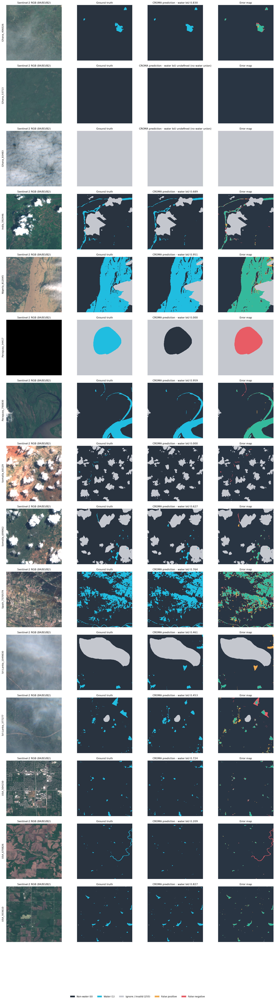

In [25]:

fig, axes, chip_ids = plot_predictions(
    predictions_dir=run_results_dir / "non_bol",
    hand_dir="datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled",
    n=15,
    seed=42,
    save_path=run_results_dir / "croma_visualization_15.png",
    show_errors=True
)

plt.show()

split,non_bol,bol
test_loss,6.827357e-02,1.024628e-01
accuracy,9.764873e-01,9.581553e-01
water_iou,8.240294e-01,7.456939e-01
nonwater_iou,9.735782e-01,9.523028e-01
miou,8.988038e-01,8.489983e-01
precision,9.279627e-01,9.538630e-01
recall,8.803441e-01,7.735961e-01
f1,9.035265e-01,8.543237e-01
omission_error,1.196559e-01,2.264039e-01
commission_error,7.203725e-02,4.613704e-02


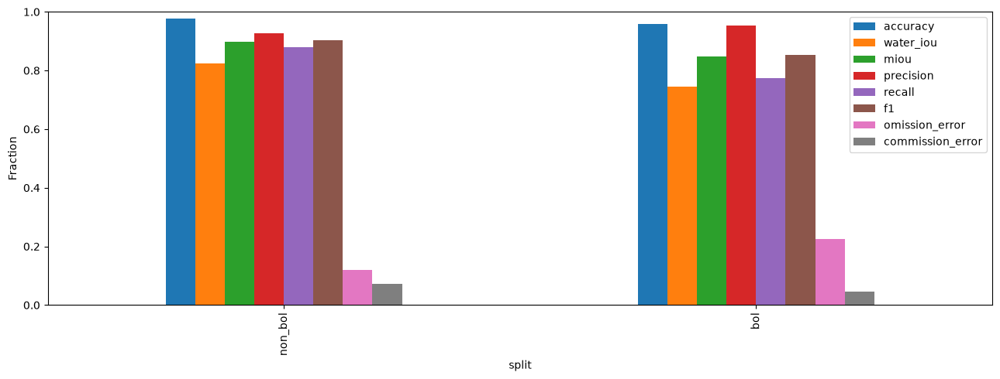

split,non_bol_original,bol_original,non_bol_usable_s2_images,bol_usable_s2_images
test_loss,6.827357e-02,1.024628e-01,NaN,NaN
accuracy,9.764873e-01,9.581553e-01,9.788741e-01,9.581553e-01
water_iou,8.240294e-01,7.456939e-01,8.393457e-01,7.456939e-01
nonwater_iou,9.735782e-01,9.523028e-01,9.762530e-01,9.523028e-01
miou,8.988038e-01,8.489983e-01,9.077994e-01,8.489983e-01
precision,9.279627e-01,9.538630e-01,9.279627e-01,9.538630e-01
recall,8.803441e-01,7.735961e-01,8.978476e-01,7.735961e-01
f1,9.035265e-01,8.543237e-01,9.126568e-01,8.543237e-01
omission_error,1.196559e-01,2.264039e-01,1.021524e-01,2.264039e-01
commission_error,7.203725e-02,4.613704e-02,7.203725e-02,4.613704e-02


In [26]:
# Recompute from confusion counts so this also works with previously saved metric dictionaries.
for metrics in (metrics_nonbolivia, metrics_bolivia):
    metrics.update(binary_metrics(*(metrics[key] for key in ("TP", "FP", "FN", "TN"))))
# Water precision/recall use water as the positive class; commission = FP/(TP+FP).
all_metrics = metric_table({"non_bol": metrics_nonbolivia, "bol": metrics_bolivia}, run_results_dir)
display(all_metrics.T)
all_metrics[["accuracy", "water_iou", "miou", "precision", "recall", "f1",
             "omission_error", "commission_error"]].plot.bar(figsize=(13, 5), ylim=(0, 1))
plt.ylabel("Fraction")
plt.tight_layout()
plt.savefig(run_results_dir / "all_metrics_comparison.png", dpi=160)
plt.show()

# Report the original split above and the usable-optical subset separately.
usable_rows = []
for split, pairs in [("non_bol", test_data_non_bolivia), ("bol", test_data_bolivia)]:
    totals = np.zeros(4, dtype=np.int64)
    excluded = []
    for x_path, y_path in pairs:
        raw, label = load_image_pair((x_path, y_path))
        if not np.isfinite(raw).all(axis=0).any():
            excluded.append(x_path.name)
            continue
        with rasterio.open(run_results_dir / split / (x_path.stem + "_prediction.tif")) as src:
            pred = src.read(1)
        valid = np.isin(label, [0, 1])
        totals += [np.count_nonzero(valid & (pred == p) & (label == t))
                   for p, t in [(1, 1), (1, 0), (0, 1), (0, 0)]]
    usable_rows.append({"split": split, "included_images": len(pairs)-len(excluded),
                        "excluded_missing_s2_images": len(excluded),
                        **binary_metrics(*totals)})
    (run_results_dir / split / "excluded_missing_s2.json").write_text(json.dumps(excluded, indent=2))
usable_summary = pd.DataFrame(usable_rows)
usable_summary.to_csv(run_results_dir / "usable_s2_summary.csv", index=False)
input_quality_comparison = metric_table({
    "non_bol_original": metrics_nonbolivia,
    "non_bol_usable_s2_images": usable_summary.set_index("split").loc["non_bol"].to_dict(),
    "bol_original": metrics_bolivia,
    "bol_usable_s2_images": usable_summary.set_index("split").loc["bol"].to_dict(),
}, run_results_dir / "input_quality_comparison")
display(input_quality_comparison.T)
